# AlphaMissense · Opus R1 · Whole-protein alignment depth

Run all cells in order. This notebook downloads the public inputs, computes the axis and performance, draws the controls, and evaluates the decision. All analysis code is contained below.

Python 3.11; packages: `numpy==1.26.4 pandas==2.2.2 scipy==1.13.1 matplotlib==3.9.4 pyarrow==16.1.0 biopython==1.85 pyhmmer==0.12.1`. Install these into the notebook kernel environment before running.


## 1. Data source / acquisition

The fixed panel contains 73 ProteinGym assays of 64 human proteins. Assay identifiers and accessions below define the selection independently of outcomes. ProteinGym v1.3 provides experimental measurements and the pinned metadata commit provides target sequences and alignment metadata. AlphaMissense provides its published amino-acid substitution scores. Downloaded files are checked by size and SHA-256 before reuse.

The public reference bundle supplies pinned Swiss-Prot canonical sequences for mapping assay-local positions to full-protein score positions. Residue analyses also use the selected raw ProteinGym alignments or AlphaFold structure files. Only the specified raw members are extracted. The data providers are [UniProt](https://www.uniprot.org/), [ProteinGym](https://proteingym.org/), and [AlphaFold DB](https://alphafold.ebi.ac.uk/).


In [1]:
ANALYSIS_ID='am-opus-r1/test-02'
RUN=1
AXIS=2
SOURCES={'metadata': {'filename': 'DMS_substitutions.csv',
              'url': 'https://raw.githubusercontent.com/OATML-Markslab/ProteinGym/144fe22b07dfaeec2b366f2346203a9838a55b4c/reference_files/DMS_substitutions.csv',
              'bytes': 208734,
              'sha256': 'a8f498011532a74aa9fe556a50555a75e928c5837d19c06a87592ae04049b308'},
 'experiments': {'filename': 'DMS_ProteinGym_v1.3_substitutions.zip',
                 'url': 'https://marks.hms.harvard.edu/proteingym/ProteinGym_v1.3/DMS_ProteinGym_substitutions.zip',
                 'bytes': 43021128,
                 'sha256': '3a83766254ac9ac9984ec25cb73c6e010ea4418f5e35f143933e6b6e6473b921'},
 'scores': {'filename': 'AlphaMissense_aa_substitutions.tsv.gz',
            'url': 'https://storage.googleapis.com/dm_alphamissense/AlphaMissense_aa_substitutions.tsv.gz',
            'bytes': 1207278510,
            'sha256': 'bc18d954a9aa6b9efab8e40d6d1912e32b774906cd3846a1f51066588e9c176d'},
 'reference_bundle': {'filename': 'alphamissense-inputs.zip',
                      'url': 'https://github.com/shreyjain11/SPECTRAagent/releases/download/notebook-inputs-2026-11-08-v1/alphamissense-inputs.zip',
                      'bytes': 998791045,
                      'sha256': '9088ab792238292f8f1ec5587f95876e0951a06484795266362d51b12641228c'}}
PANEL=[{'assay': 'A4_HUMAN_Seuma_2022', 'acc': 'P05067'},
 {'assay': 'ACE2_HUMAN_Chan_2020', 'acc': 'Q9BYF1'},
 {'assay': 'ADRB2_HUMAN_Jones_2020', 'acc': 'P07550'},
 {'assay': 'AICDA_HUMAN_Gajula_2014_3cycles', 'acc': 'Q9GZX7'},
 {'assay': 'B2L11_HUMAN_Dutta_2010_binding-Mcl-1', 'acc': 'O43521'},
 {'assay': 'BRCA1_HUMAN_Findlay_2018', 'acc': 'P38398'},
 {'assay': 'BRCA2_HUMAN_Erwood_2022_HEK293T', 'acc': 'P51587'},
 {'assay': 'CALM1_HUMAN_Weile_2017', 'acc': 'P0DP23'},
 {'assay': 'CAR11_HUMAN_Meitlis_2020_gof', 'acc': 'Q9BXL7'},
 {'assay': 'CAR11_HUMAN_Meitlis_2020_lof', 'acc': 'Q9BXL7'},
 {'assay': 'CBPA2_HUMAN_Tsuboyama_2023_1O6X', 'acc': 'P48052'},
 {'assay': 'CBS_HUMAN_Sun_2020', 'acc': 'P35520'},
 {'assay': 'CBX4_HUMAN_Tsuboyama_2023_2K28', 'acc': 'O00257'},
 {'assay': 'CCR5_HUMAN_Gill_2023', 'acc': 'P51681'},
 {'assay': 'CD19_HUMAN_Klesmith_2019_FMC_singles', 'acc': 'P15391'},
 {'assay': 'CP2C9_HUMAN_Amorosi_2021_abundance', 'acc': 'P11712'},
 {'assay': 'CP2C9_HUMAN_Amorosi_2021_activity', 'acc': 'P11712'},
 {'assay': 'DLG4_HUMAN_Faure_2021', 'acc': 'P78352'},
 {'assay': 'DNJA1_HUMAN_Tsuboyama_2023_2LO1', 'acc': 'P31689'},
 {'assay': 'EPHB2_HUMAN_Tsuboyama_2023_1F0M', 'acc': 'P29323'},
 {'assay': 'ERBB2_HUMAN_Elazar_2016', 'acc': 'P04626'},
 {'assay': 'FKBP3_HUMAN_Tsuboyama_2023_2KFV', 'acc': 'Q00688'},
 {'assay': 'GDIA_HUMAN_Silverstein_2021', 'acc': 'P31150'},
 {'assay': 'GRB2_HUMAN_Faure_2021', 'acc': 'P62993'},
 {'assay': 'HEM3_HUMAN_Loggerenberg_2023', 'acc': 'P08397'},
 {'assay': 'HMDH_HUMAN_Jiang_2019', 'acc': 'P04035'},
 {'assay': 'HXK4_HUMAN_Gersing_2022_activity', 'acc': 'P35557'},
 {'assay': 'HXK4_HUMAN_Gersing_2023_abundance', 'acc': 'P35557'},
 {'assay': 'KCNH2_HUMAN_Kozek_2020', 'acc': 'Q12809'},
 {'assay': 'LYAM1_HUMAN_Elazar_2016', 'acc': 'P14151'},
 {'assay': 'MET_HUMAN_Estevam_2023', 'acc': 'P08581'},
 {'assay': 'MK01_HUMAN_Brenan_2016', 'acc': 'P28482'},
 {'assay': 'MSH2_HUMAN_Jia_2020', 'acc': 'P43246'},
 {'assay': 'MTHR_HUMAN_Weile_2021', 'acc': 'P42898'},
 {'assay': 'NPC1_HUMAN_Erwood_2022_HEK293T', 'acc': 'O15118'},
 {'assay': 'NPC1_HUMAN_Erwood_2022_RPE1', 'acc': 'O15118'},
 {'assay': 'NUD15_HUMAN_Suiter_2020', 'acc': 'Q9NV35'},
 {'assay': 'OBSCN_HUMAN_Tsuboyama_2023_1V1C', 'acc': 'Q5VST9'},
 {'assay': 'OPSD_HUMAN_Wan_2019', 'acc': 'P08100'},
 {'assay': 'OTC_HUMAN_Lo_2023', 'acc': 'P00480'},
 {'assay': 'OTU7A_HUMAN_Tsuboyama_2023_2L2D', 'acc': 'Q8TE49'},
 {'assay': 'P53_HUMAN_Kotler_2018', 'acc': 'P04637'},
 {'assay': 'PAI1_HUMAN_Huttinger_2021', 'acc': 'P05121'},
 {'assay': 'PIN1_HUMAN_Tsuboyama_2023_1I6C', 'acc': 'Q13526'},
 {'assay': 'PPARG_HUMAN_Majithia_2016', 'acc': 'P37231'},
 {'assay': 'PPM1D_HUMAN_Miller_2022', 'acc': 'O15297'},
 {'assay': 'PR40A_HUMAN_Tsuboyama_2023_1UZC', 'acc': 'O75400'},
 {'assay': 'PRKN_HUMAN_Clausen_2023', 'acc': 'O60260'},
 {'assay': 'PTEN_HUMAN_Matreyek_2021', 'acc': 'P60484'},
 {'assay': 'PTEN_HUMAN_Mighell_2018', 'acc': 'P60484'},
 {'assay': 'RAF1_HUMAN_Zinkus-Boltz_2019', 'acc': 'P04049'},
 {'assay': 'RASH_HUMAN_Bandaru_2017', 'acc': 'P01112'},
 {'assay': 'RD23A_HUMAN_Tsuboyama_2023_1IFY', 'acc': 'P54725'},
 {'assay': 'S22A1_HUMAN_Yee_2023_abundance', 'acc': 'O15245'},
 {'assay': 'S22A1_HUMAN_Yee_2023_activity', 'acc': 'O15245'},
 {'assay': 'SC6A4_HUMAN_Young_2021', 'acc': 'P31645'},
 {'assay': 'SCN5A_HUMAN_Glazer_2019', 'acc': 'Q14524'},
 {'assay': 'SERC_HUMAN_Xie_2023', 'acc': 'Q9Y617'},
 {'assay': 'SHOC2_HUMAN_Kwon_2022', 'acc': 'Q9UQ13'},
 {'assay': 'SOX30_HUMAN_Tsuboyama_2023_7JJK', 'acc': 'O94993'},
 {'assay': 'SRC_HUMAN_Ahler_2019', 'acc': 'P12931'},
 {'assay': 'SRC_HUMAN_Chakraborty_2023_binding-DAS_25uM', 'acc': 'P12931'},
 {'assay': 'SRC_HUMAN_Nguyen_2022', 'acc': 'P12931'},
 {'assay': 'SUMO1_HUMAN_Weile_2017', 'acc': 'P63165'},
 {'assay': 'TADBP_HUMAN_Bolognesi_2019', 'acc': 'Q13148'},
 {'assay': 'TPK1_HUMAN_Weile_2017', 'acc': 'Q9H3S4'},
 {'assay': 'TPMT_HUMAN_Matreyek_2018', 'acc': 'P51580'},
 {'assay': 'UBC9_HUMAN_Weile_2017', 'acc': 'P63279'},
 {'assay': 'UBE4B_HUMAN_Tsuboyama_2023_3L1X', 'acc': 'O95155'},
 {'assay': 'UBR5_HUMAN_Tsuboyama_2023_1I2T', 'acc': 'O95071'},
 {'assay': 'VKOR1_HUMAN_Chiasson_2020_abundance', 'acc': 'Q9BQB6'},
 {'assay': 'VKOR1_HUMAN_Chiasson_2020_activity', 'acc': 'Q9BQB6'},
 {'assay': 'YAP1_HUMAN_Araya_2012', 'acc': 'P46937'}]

from pathlib import Path
from collections import Counter
import concurrent.futures, csv, gzip, hashlib, io, json, os, platform, shutil, tarfile, time, urllib.request, zipfile
import numpy as np
import pandas as pd
import scipy
from scipy.stats import spearmanr, wilcoxon
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

INPUT=Path(os.environ.get('AM_OPUS_INPUTS', Path.cwd()/'inputs'))
INPUT.mkdir(parents=True,exist_ok=True)
OUT=Path.cwd()/f'{ANALYSIS_ID.replace("/","-")}-outputs'
OUT.mkdir(parents=True,exist_ok=True)
AA='ACDEFGHIKLMNPQRSTVWY'
pd.set_option('display.max_columns',30)
pd.set_option('display.max_rows',90)

def show_figure(figure):
    buffer=io.BytesIO()
    figure.savefig(buffer,format='png',dpi=130,bbox_inches='tight')
    display(Image(data=buffer.getvalue()))
    plt.close(figure)

def sha256(path):
    digest=hashlib.sha256()
    with open(path,'rb') as handle:
        for block in iter(lambda:handle.read(8*1024*1024),b''):digest.update(block)
    return digest.hexdigest()

def acquire(record):
    path=INPUT/record['filename']
    if path.is_file() and path.stat().st_size==record['bytes'] and sha256(path)==record['sha256']:
        return path
    part=path.with_name(path.name+f'.{os.getpid()}.part')
    with urllib.request.urlopen(record['url'],timeout=120) as response,open(part,'wb') as target:
        shutil.copyfileobj(response,target,8*1024*1024)
    assert part.stat().st_size==record['bytes'],record['filename']
    assert sha256(part)==record['sha256'],record['filename']
    part.replace(path)
    return path

def extract_member(archive,record):
    destination=INPUT/Path(record['member']).name
    if destination.exists() and sha256(destination)==record['sha256']:return destination
    temporary=destination.with_name(destination.name+f'.{os.getpid()}.part')
    with zipfile.ZipFile(archive) as bundle,bundle.open(record['member']) as source,open(temporary,'wb') as target:
        shutil.copyfileobj(source,target,8*1024*1024)
    assert temporary.stat().st_size==record['bytes']
    assert sha256(temporary)==record['sha256']
    temporary.replace(destination)
    return destination

display(pd.DataFrame(SOURCES).T[['filename','bytes','sha256','url']])
paths={name:acquire(record) for name,record in SOURCES.items()}
print('Source files downloaded or verified:',len(paths))
print('Python',platform.python_version(),'NumPy',np.__version__,'pandas',pd.__version__,'SciPy',scipy.__version__)


,filename,bytes,sha256,url
metadata,DMS_substitutions.csv,208734,a8f498011532a74aa9fe556a50555a75e928c5837d19c0...,https://raw.githubusercontent.com/OATML-Marksl...
experiments,DMS_ProteinGym_v1.3_substitutions.zip,43021128,3a83766254ac9ac9984ec25cb73c6e010ea4418f5e35f1...,https://marks.hms.harvard.edu/proteingym/Prote...
scores,AlphaMissense_aa_substitutions.tsv.gz,1207278510,bc18d954a9aa6b9efab8e40d6d1912e32b774906cd3846...,https://storage.googleapis.com/dm_alphamissens...
reference_bundle,alphamissense-inputs.zip,998791045,9088ab792238292f8f1ec5587f95876e0951a064847952...,https://github.com/shreyjain11/SPECTRAagent/re...


Source files downloaded or verified: 4
Python 3.11.13 NumPy 1.26.4 pandas 2.2.2 SciPy 1.13.1


In [2]:
swissprot_path=extract_member(paths["reference_bundle"],{'bytes': 93706469,
 'member': 'am-opus-r1/data/uniprot_sprot.fasta.gz',
 'sha256': 'b774748a050fd3de0bf2ad49b359ed59a2c2b02c89df3fe0679fafa446751794'})
print(swissprot_path.name)


uniprot_sprot.fasta.gz


## 2. Data processing

Read the raw assay CSVs. Retain single amino-acid substitutions with numeric experimental measurements and a matching wild-type residue in the declared target sequence. Every exclusion count is displayed; no saved per-variant analysis table is used.


In [3]:
panel=pd.DataFrame(PANEL)
metadata=pd.read_csv(paths['metadata']).rename(columns={'DMS_id':'assay'})
metadata=panel.merge(metadata,on='assay',validate='one_to_one')
assert len(metadata)==len(panel)
assert metadata.groupby('acc').target_seq.nunique().max()==1
from Bio import SeqIO
canonical_sequences={}
wanted_accessions=set(panel.acc)
with gzip.open(swissprot_path,'rt') as handle:
    for record in SeqIO.parse(handle,'fasta'):
        accession=record.id.split('|')[1]
        if accession in wanted_accessions:canonical_sequences[accession]=str(record.seq)
assert wanted_accessions<=set(canonical_sequences),'A panel accession is absent from the pinned Swiss-Prot FASTA'
variant_tables=[]; processing_counts=[]
with zipfile.ZipFile(paths['experiments']) as archive:
    for record in metadata.itertuples(index=False):
        member=f'DMS_ProteinGym_substitutions/{record.assay}.csv'
        with archive.open(member) as handle:raw=pd.read_csv(handle)
        frame=raw.loc[raw.mutant.str.fullmatch(r'[ACDEFGHIKLMNPQRSTVWY][0-9]+[ACDEFGHIKLMNPQRSTVWY]',na=False),['mutant','DMS_score']].copy()
        frame['DMS_score']=pd.to_numeric(frame.DMS_score,errors='coerce')
        frame=frame.dropna(subset=['DMS_score'])
        frame['position']=frame.mutant.str[1:-1].astype(int)
        frame['wt']=frame.mutant.str[0];frame['alt']=frame.mutant.str[-1]
        valid=[1<=p<=len(record.target_seq) and record.target_seq[p-1]==w for p,w in zip(frame.position,frame.wt)]
        mismatches=int((~np.asarray(valid)).sum())
        frame=frame.loc[valid].copy()
        assert not frame.mutant.duplicated().any(),record.assay
        frame['assay']=record.assay;frame['acc']=record.acc
        variant_tables.append(frame)
        processing_counts.append(dict(assay=record.assay,raw_rows=len(raw),single_valid_substitutions=len(frame),target_residue_mismatches=mismatches))
variants=pd.concat(variant_tables,ignore_index=True)
variants=variants.merge(metadata[['assay','UniProt_ID','coarse_selection_type','MSA_filename','MSA_start','MSA_end','MSA_len','MSA_N_eff','MSA_Neff_L']],on='assay',validate='many_to_one')
processing=pd.DataFrame(processing_counts)
processing.to_csv(OUT/'input_processing_counts.csv',index=False)
display(processing)
print('Variants before released-score join:',len(variants),'Assays:',variants.assay.nunique(),'Proteins:',variants.acc.nunique())


,assay,raw_rows,single_valid_substitutions,target_residue_mismatches
0,A4_HUMAN_Seuma_2022,14811,796,0
1,ACE2_HUMAN_Chan_2020,2223,2223,0
2,ADRB2_HUMAN_Jones_2020,7800,7800,0
3,AICDA_HUMAN_Gajula_2014_3cycles,209,209,0
4,B2L11_HUMAN_Dutta_2010_binding-Mcl-1,170,170,0
5,BRCA1_HUMAN_Findlay_2018,1837,1837,0
6,BRCA2_HUMAN_Erwood_2022_HEK293T,265,265,0
7,CALM1_HUMAN_Weile_2017,1813,1813,0
8,CAR11_HUMAN_Meitlis_2020_gof,2374,2374,0
9,CAR11_HUMAN_Meitlis_2020_lof,2395,2395,0


Variants before released-score join: 273135 Assays: 73 Proteins: 64


## 3. Axis definition and level construction


The axis is the released ProteinGym effective sequence count divided by alignment length (`MSA_Neff_L`). It is evaluated continuously across assays; no discrete level construction was used for this screen. The metadata measurements and their normalization are displayed. Protein-separated discovery and confirmation groups are fixed without examining outcomes.


In [4]:
def rank_position_levels(frame,feature,nlevels):
    rows=[]
    for assay,group in frame.groupby('assay',sort=True):
        positions=group[['position',feature]].dropna().drop_duplicates('position')
        if positions[feature].nunique()<nlevels:continue
        positions=positions.sort_values([feature,'position'],kind='stable')
        positions['level']=pd.qcut(positions[feature].rank(method='first'),nlevels,labels=False)
        group=group.merge(positions[['position','level']],on='position',how='inner',validate='many_to_one')
        group['scheme']=f'{nlevels} levels';rows.append(group)
    return pd.concat(rows,ignore_index=True)

if RUN==1:
    discovery={acc for acc in variants.acc.unique() if int(hashlib.md5(acc.encode()).hexdigest(),16)%2==0}
else:
    accessions=np.array(sorted(variants.acc.unique()))
    if AXIS==1:accessions=np.array(sorted(variants.loc[variants.plddt.notna(),'acc'].unique()))
    np.random.default_rng(7).shuffle(accessions)
    discovery=set(accessions[:len(accessions)//2])
variants['split']=np.where(variants.acc.isin(discovery),'discovery','confirmation')

depth_metadata=metadata[['assay','acc','MSA_N_eff','MSA_len','MSA_Neff_L']].copy()
depth_metadata['ratio_from_metadata']=depth_metadata.MSA_N_eff/depth_metadata.MSA_len
depth_metadata.to_csv(OUT/'axis_definition.csv',index=False)
display(depth_metadata)


,assay,acc,MSA_N_eff,MSA_len,MSA_Neff_L,ratio_from_metadata
0,A4_HUMAN_Seuma_2022,P05067,62.3,770,0.08,0.080909
1,ACE2_HUMAN_Chan_2020,Q9BYF1,1584.2,805,1.97,1.967950
2,ADRB2_HUMAN_Jones_2020,P07550,28078.5,413,67.99,67.986683
3,AICDA_HUMAN_Gajula_2014_3cycles,Q9GZX7,3643.3,198,18.40,18.400505
4,B2L11_HUMAN_Dutta_2010_binding-Mcl-1,O43521,88.7,198,0.45,0.447980
5,BRCA1_HUMAN_Findlay_2018,P38398,100.2,1863,0.05,0.053784
6,BRCA2_HUMAN_Erwood_2022_HEK293T,P51587,72.1,3418,0.02,0.021094
7,CALM1_HUMAN_Weile_2017,P0DP23,28424.0,149,190.77,190.765101
8,CAR11_HUMAN_Meitlis_2020_gof,Q9BXL7,42.1,1154,0.04,0.036482
9,CAR11_HUMAN_Meitlis_2020_lof,Q9BXL7,42.1,1154,0.04,0.036482


## 4. Model results or released scores

Read the downloaded official AlphaMissense table and align each assay target to its pinned Swiss-Prot canonical sequence, then join on UniProt accession plus the mapped full-protein amino-acid substitution. The code displays mapping methods and excluded variants. AlphaMissense is used as released; this analysis does not fine-tune it. Performance is absolute Spearman correlation against each assay’s experimental scores, so assays with opposite effect conventions remain comparable.


In [5]:
# Read the published AlphaMissense score table directly. No model fitting occurs.
# Map assay-local numbering to the canonical sequence in the pinned Swiss-Prot FASTA.
wanted=set(variants.acc)
released=[]
with gzip.open(paths['scores'],'rt') as handle:
    for line in handle:
        if line.startswith('#'):continue
        header=line.rstrip('\n').split('\t');break
    columns={name:header.index(name) for name in ['uniprot_id','protein_variant','am_pathogenicity']}
    for line in handle:
        accession=line.split('\t',1)[0]
        if accession not in wanted:continue
        values=line.rstrip('\n').split('\t')
        variant=values[columns['protein_variant']]
        released.append((accession,variant,float(values[columns['am_pathogenicity']])))
released=pd.DataFrame(released,columns=['acc','am_variant','am_pathogenicity'])
assert not released.duplicated(['acc','am_variant']).any()
from Bio import Align
score_aligner=Align.PairwiseAligner(mode='local',match_score=2,mismatch_score=-1,open_gap_score=-10,extend_gap_score=-1)
variants['am_variant']=None
score_mapping=[]
for assay,group in variants.groupby('assay'):
    accession=group.acc.iloc[0]
    target=metadata.set_index('assay').loc[assay,'target_seq']
    reference=canonical_sequences[accession]
    offset=reference.find(target);position_map={}
    if offset>=0:
        position_map={position+1:offset+position+1 for position in range(len(target))}
        method='exact target substring in pinned Swiss-Prot canonical sequence'
    else:
        alignment=score_aligner.align(target,reference)[0]
        for (t0,t1),(r0,r1) in zip(*alignment.aligned):
            for k in range(t1-t0):position_map[t0+k+1]=r0+k+1
        method='local target-to-Swiss-Prot canonical sequence alignment'
    mapped=[]
    for position,wildtype,alternate in zip(group.position,group.wt,group.alt):
        canonical_position=position_map.get(position)
        mapped.append(f'{wildtype}{canonical_position}{alternate}' if canonical_position is not None and reference[canonical_position-1]==wildtype else None)
    variants.loc[group.index,'am_variant']=mapped
    score_mapping.append(dict(assay=assay,acc=accession,method=method,target_length=len(target),canonical_length=len(reference),mapped_variants=sum(value is not None for value in mapped),unmapped_variants=sum(value is None for value in mapped)))
mapping_table=pd.DataFrame(score_mapping)
mapping_table.to_csv(OUT/'released_score_position_mapping.csv',index=False)
display(mapping_table)
before=len(variants)
variants=variants.merge(released,on=['acc','am_variant'],how='inner',validate='many_to_one')
assert len(variants)>0
print('Published score join:',len(variants),'variants; missing scores:',before-len(variants))
display(variants.groupby('split').agg(variants=('mutant','size'),assays=('assay','nunique'),proteins=('acc','nunique')))


,assay,acc,method,target_length,canonical_length,mapped_variants,unmapped_variants
0,A4_HUMAN_Seuma_2022,P05067,exact target substring in pinned Swiss-Prot ca...,770,770,796,0
1,ACE2_HUMAN_Chan_2020,Q9BYF1,exact target substring in pinned Swiss-Prot ca...,805,805,2223,0
2,ADRB2_HUMAN_Jones_2020,P07550,exact target substring in pinned Swiss-Prot ca...,413,413,7800,0
3,AICDA_HUMAN_Gajula_2014_3cycles,Q9GZX7,exact target substring in pinned Swiss-Prot ca...,198,198,209,0
4,B2L11_HUMAN_Dutta_2010_binding-Mcl-1,O43521,exact target substring in pinned Swiss-Prot ca...,198,198,170,0
5,BRCA1_HUMAN_Findlay_2018,P38398,exact target substring in pinned Swiss-Prot ca...,1863,1863,1837,0
6,BRCA2_HUMAN_Erwood_2022_HEK293T,P51587,exact target substring in pinned Swiss-Prot ca...,3418,3418,265,0
7,CALM1_HUMAN_Weile_2017,P0DP23,exact target substring in pinned Swiss-Prot ca...,149,149,1813,0
8,CAR11_HUMAN_Meitlis_2020_gof,Q9BXL7,exact target substring in pinned Swiss-Prot ca...,1154,1154,2374,0
9,CAR11_HUMAN_Meitlis_2020_lof,Q9BXL7,exact target substring in pinned Swiss-Prot ca...,1154,1154,2395,0


Published score join: 273135 variants; missing scores: 0


,variants,assays,proteins
split,,,
confirmation,133682,35,30
discovery,139453,38,34


In [6]:
def agreement(group,column):
    usable=group[[column,'DMS_score']].dropna()
    if len(usable)<50 or usable[column].nunique()<3 or usable.DMS_score.nunique()<6:return np.nan
    return abs(float(spearmanr(usable[column],usable.DMS_score).statistic))
assay_results=[]
for assay,group in variants.groupby('assay'):
    assay_results.append(dict(assay=assay,acc=group.acc.iloc[0],agreement=agreement(group,'am_pathogenicity'),depth=group.MSA_Neff_L.iloc[0],selection=group.coarse_selection_type.iloc[0],split=group.split.iloc[0],n_variants=len(group)))
accuracy=pd.DataFrame(assay_results).dropna(subset=['depth','agreement'])
accuracy.to_csv(OUT/'assay_performance.csv',index=False)
variants[['assay','acc','mutant','DMS_score','am_pathogenicity','MSA_Neff_L','split']].to_parquet(OUT/'variant_scores.parquet',index=False)
display(accuracy)


,assay,acc,agreement,depth,selection,split,n_variants
0,A4_HUMAN_Seuma_2022,P05067,0.495208,0.08,Stability,discovery,796
1,ACE2_HUMAN_Chan_2020,Q9BYF1,0.248442,1.97,Binding,discovery,2223
2,ADRB2_HUMAN_Jones_2020,P07550,0.559879,67.99,Activity,discovery,7800
3,AICDA_HUMAN_Gajula_2014_3cycles,Q9GZX7,0.488319,18.40,Activity,confirmation,209
4,B2L11_HUMAN_Dutta_2010_binding-Mcl-1,O43521,0.417427,0.45,Binding,discovery,170
5,BRCA1_HUMAN_Findlay_2018,P38398,0.579581,0.05,OrganismalFitness,discovery,1837
6,BRCA2_HUMAN_Erwood_2022_HEK293T,P51587,0.433445,0.02,OrganismalFitness,confirmation,265
7,CALM1_HUMAN_Weile_2017,P0DP23,0.194221,190.77,OrganismalFitness,discovery,1813
8,CAR11_HUMAN_Meitlis_2020_gof,Q9BXL7,0.265108,0.04,OrganismalFitness,discovery,2374
9,CAR11_HUMAN_Meitlis_2020_lof,Q9BXL7,0.415553,0.04,OrganismalFitness,discovery,2395


## 5. Curves and controls


Plot each assay and assess the depth–performance association across all assays, after removing stability assays, within stability assays, and in the protein-separated discovery and confirmation groups.


,subset,n_assays,rho,p
0,All,73,0.046035,0.698948
1,Excluding stability,59,0.154957,0.241248
2,Stability only,14,-0.243956,0.400625
3,Discovery,38,0.057896,0.729895
4,Confirmation,35,0.008685,0.960507


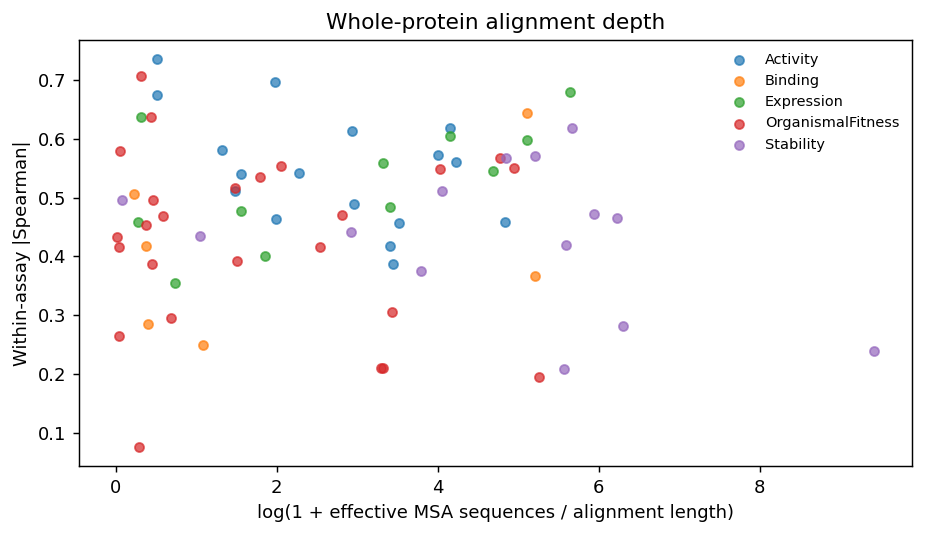

In [7]:
depth_controls=[]
for label,subset in [('All',accuracy),('Excluding stability',accuracy[accuracy.selection!='Stability']),('Stability only',accuracy[accuracy.selection=='Stability']),('Discovery',accuracy[accuracy.split=='discovery']),('Confirmation',accuracy[accuracy.split=='confirmation'])]:
    rho,p=spearmanr(subset.depth,subset.agreement) if len(subset)>2 else (np.nan,np.nan)
    depth_controls.append(dict(subset=label,n_assays=len(subset),rho=rho,p=p))
depth_controls=pd.DataFrame(depth_controls)
depth_controls.to_csv(OUT/'depth_controls.csv',index=False)
display(depth_controls)
fig,ax=plt.subplots(figsize=(7,4),constrained_layout=True)
for selection,group in accuracy.groupby('selection'):
    ax.scatter(np.log1p(group.depth),group.agreement,label=selection,alpha=.7,s=25)
ax.set(xlabel='log(1 + effective MSA sequences / alignment length)',ylabel='Within-assay |Spearman|',title='Whole-protein alignment depth')
ax.legend(frameon=False,fontsize=8)
show_figure(fig)


## 6. Decision and reason


In [8]:
pooled=depth_controls.loc[depth_controls.subset=='All'].iloc[0]
controlled=depth_controls.loc[depth_controls.subset=='Excluding stability'].iloc[0]
consistent=pooled.rho>0 and controlled.rho>0 and controlled.p<.05
decision='Accept a positive depth–performance association' if consistent else 'Reject whole-protein depth as a supported positive performance axis'
display(Markdown(f'**{decision}.** The pooled Spearman association is {pooled.rho:.3f} (p={pooled.p:.3g}); after excluding stability assays it is {controlled.rho:.3f} (p={controlled.p:.3g}). The decision follows these calculated results.'))


**Reject whole-protein depth as a supported positive performance axis.** The pooled Spearman association is 0.046 (p=0.699); after excluding stability assays it is 0.155 (p=0.241). The decision follows these calculated results.

In [9]:
files=[dict(path=str(path.relative_to(OUT)),bytes=path.stat().st_size,sha256=sha256(path)) for path in sorted(OUT.iterdir()) if path.is_file() and path.name!='OUTPUT_MANIFEST.json']
(OUT/'OUTPUT_MANIFEST.json').write_text(json.dumps(files,indent=2)+'\n')
print('Outputs:',str(OUT.resolve()))


Outputs: /ewsc/yektefai/spectra_runs/all_axes_inline_20261109/alphamissense/am-opus-r1/am-opus-r1-test-02-outputs
